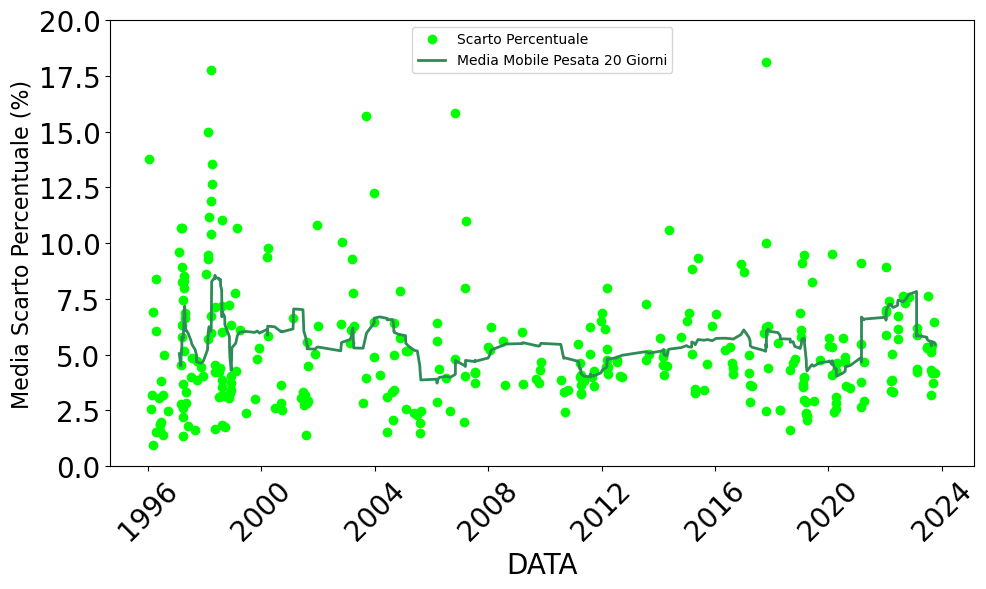

Media pesata complessiva: 5.53%
Media pesata Inverno: 7.05%
Media pesata Primavera: 5.59%
Media pesata Estate: 4.14%
Media pesata Autunno: 5.47%
stagione   1   2   3  4
anno                   
1996       4   9   5  1
1997       4  20   3  3
1998      11  11  10  5
1999       4   1   1  2
2000       0   3   1  3
2001       3   1   9  1
2002       1   0   0  2
2003       4   4   1  2
2004       0   1   4  5
2005       2   2   4  0
2006       0   4   2  2
2007       2   3   3  0
2008       2   0   2  0
2009       0   2   0  4
2010       0   0   2  2
2011       1   8   3  2
2012       3   6   3  1
2013       0   0   2  1
2014       2   6   0  1
2015       1   5   1  2
2016       1   1   4  1
2017       1   5   0  7
2018       0   3   2  2
2019      10   5   2  1
2020       5   6   4  1
2021       2   5   0  0
2022       5   5   4  2
2023       4   0   9  3


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Funzione per calcolare la media mobile pesata
def media_mobile_pesata(df, window):
    df['media_mobile_pesata'] = df['scarto_percentuale'].rolling(window=window, min_periods=1).mean()
    df.loc[:window-2, 'media_mobile_pesata'] = float('nan')
    return df

# Funzione per calcolare la media pesata complessiva
def calcola_media_pesata_complessiva(df):
    return df['scarto_percentuale'].mean()

# Funzione per calcolare la media pesata stagionale
def calcola_media_stagionale(df):
    df['stagione'] = pd.to_datetime(df['data']).dt.month % 12 // 3 + 1
    stagioni = {1: 'Inverno', 2: 'Primavera', 3: 'Estate', 4: 'Autunno'}
    media_stagionale = df.groupby('stagione')['scarto_percentuale'].mean().rename(index=stagioni).to_dict()
    return media_stagionale

# Funzione per calcolare gli scarti percentuali e restituire un DataFrame aggregato
def calcola_media_scarto(file_csv, nomi_colonne_selezionati):
    df = pd.read_csv(file_csv, sep=';', decimal='.')
    df['data'] = pd.to_datetime(df['data'], format='%d/%m/%Y')

    # Filtra il DataFrame per includere solo i nomi specificati
    df_filtrato = df[df['nome'].isin(nomi_colonne_selezionati)].copy()

    # Converti le colonne 'rad' e 'shortwave_radiation' in numerico, sostituendo errori con NaN
    df_filtrato['rad'] = pd.to_numeric(df_filtrato['rad'], errors='coerce')
    df_filtrato['shortwave_radiation'] = pd.to_numeric(df_filtrato['shortwave_radiation'], errors='coerce')

    # Rimuovi le righe con valori NaN in 'rad' o 'shortwave_radiation'
    df_filtrato.dropna(subset=['rad', 'shortwave_radiation'], inplace=True)

    # Calcola lo scarto percentuale tra 'rad' e 'shortwave_radiation'
    df_filtrato['scarto_percentuale'] = abs(df_filtrato['rad'] - df_filtrato['shortwave_radiation']) / df_filtrato['shortwave_radiation'] * 100
    
    # Raggruppa per data e calcola la media degli scarti percentuali
    df_aggregato = df_filtrato.groupby('data').agg(
        scarto_percentuale=('scarto_percentuale', 'mean')
    ).reset_index()

    return df_aggregato

# Funzione per contare le date per ogni stagione in ogni anno
def conta_date_per_stagione(df):
    df['anno'] = df['data'].dt.year
    df['stagione'] = pd.to_datetime(df['data']).dt.month % 12 // 3 + 1
    conteggio = df.groupby(['anno', 'stagione']).size().unstack(fill_value=0)
    print(conteggio)

# Funzione principale per la visualizzazione del grafico
def plot_scarto_percentuale(media_scarto_df, window):
    media_scarto_df = media_mobile_pesata(media_scarto_df, window)
          
    media_pesata_complessiva = calcola_media_pesata_complessiva(media_scarto_df)
    media_stagionale = calcola_media_stagionale(media_scarto_df)

    plt.figure(figsize=(10, 6))
    plt.plot(media_scarto_df['data'], media_scarto_df['scarto_percentuale'], marker='o', linestyle='None', color='#00ff00', label='Scarto Percentuale')
    plt.plot(media_scarto_df['data'], media_scarto_df['media_mobile_pesata'], color='#2e8b57', linestyle='-', linewidth=2, label=f'Media Mobile Pesata {window} Giorni')
    plt.xlabel('DATA', fontsize=20)
    plt.ylabel('Media Scarto Percentuale (%)', fontsize=16)
    plt.ylim(0, 20)
    plt.xticks(rotation=45, fontsize=20)
    plt.yticks(fontsize=20)
    
    plt.legend()
    plt.tight_layout()
    plt.savefig('scarto_percentuale_stazioni_ERA5.png', bbox_inches='tight')
    plt.show()

    print(f"Media pesata complessiva: {media_pesata_complessiva:.2f}%")
    for stagione, media in media_stagionale.items():
        print(f"Media pesata {stagione}: {media:.2f}%")

# Esecuzione del codice
file_csv = r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\ARPA\ERA_PV_stazioni_clearsky_daily.csv'  # Inserisci qui il percorso del tuo file CSV
nomi_colonne_selezionati =  ['ALBA','CASALE_MONFERRATO', 'ASTI', 'ALESSANDRI','AVIGLIANA','BASALUZZO','BUTTIGLIERA','BORGOFRANCO_IVREA','BRA', 'CANDIA_CANAVESE', 'CARMAGNOLA','COSTIGLIOLE_SALUZZO','CUMIANA','CUNEO', 'FOSSANO','ISOLA_SANTOANTONIO','MONCALIERI','NOVI_LIGURE','SALICETO','TREISO','VERCELLI','VEROLENGO','VILLANOVA_SOLARO']    # Sostituisci con i nomi che desideri includere

media_scarto_df = calcola_media_scarto(file_csv, nomi_colonne_selezionati)

# Visualizza il grafico con la media mobile pesata e la media pesata complessiva
plot_scarto_percentuale(media_scarto_df, window=20)

# Conta le date per ogni stagione in ogni anno
conta_date_per_stagione(media_scarto_df)
